Cette démonstration s'appuie sur un [exemple de scikit-learn](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_iris.html).

In [1]:
%matplotlib inline

# Clustering k-means

Les données : les 150 fleurs d'[Iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html), décrites par 4 variables (longueur et largeur du sépale et du pétale), de trois espèces. K-means ne voit pas les espèces : elles servent seulement à juger le résultat.

On compare trois modèles, dans l'ordre des graphiques :

1. 3 clusters ;
2. 3 clusters, avec une mauvaise initialisation : `init="random"` (centroïdes initiaux tirés au hasard parmi les points, au lieu de k-means++) et `n_init=1` (un seul lancement) ;
3. 8 clusters ;

puis la vérité terrain, les espèces.

`n_init` est le nombre de lancements depuis des centroïdes initiaux différents : k-means garde celui de plus faible inertie. Par défaut (`n_init="auto"`, depuis scikit-learn 1.4), c'est 1 lancement avec k-means++ et 10 avec `init="random"`.

In [2]:
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

iris = datasets.load_iris()
X = iris.data  # 150 fleurs, 4 variables (longueur et largeur du sépale et du pétale)
y = iris.target  # l'espèce (0, 1 ou 2), que k-means ne voit pas

## Trois modèles

Pour chaque modèle :

- l'inertie, ce que k-means minimise : la somme des carrés des distances de chaque point à son centroïde ;
- l'indice de Rand ajusté (ARI), qui compare les clusters aux espèces : 1 = partition identique, ≈ 0 = hasard.

In [3]:
modeles = {
  "3 clusters": KMeans(n_clusters=3, random_state=0),
  "3 clusters, mauvaise initialisation": KMeans(
    n_clusters=3, init="random", n_init=1, random_state=5
  ),
  "8 clusters": KMeans(n_clusters=8, random_state=0),
}
for titre, modele in modeles.items():
  modele.fit(X)
  ari = adjusted_rand_score(y, modele.labels_)
  print(f"{titre} : inertie {modele.inertia_:.1f}, ARI {ari:.2f}")

3 clusters : inertie 78.9, ARI 0.72
3 clusters, mauvaise initialisation : inertie 142.8, ARI 0.43
8 clusters : inertie 30.1, ARI 0.46


Les quatre partitions, sur trois des quatre variables (les couleurs des clusters sont arbitraires : seuls les groupes comptent) :

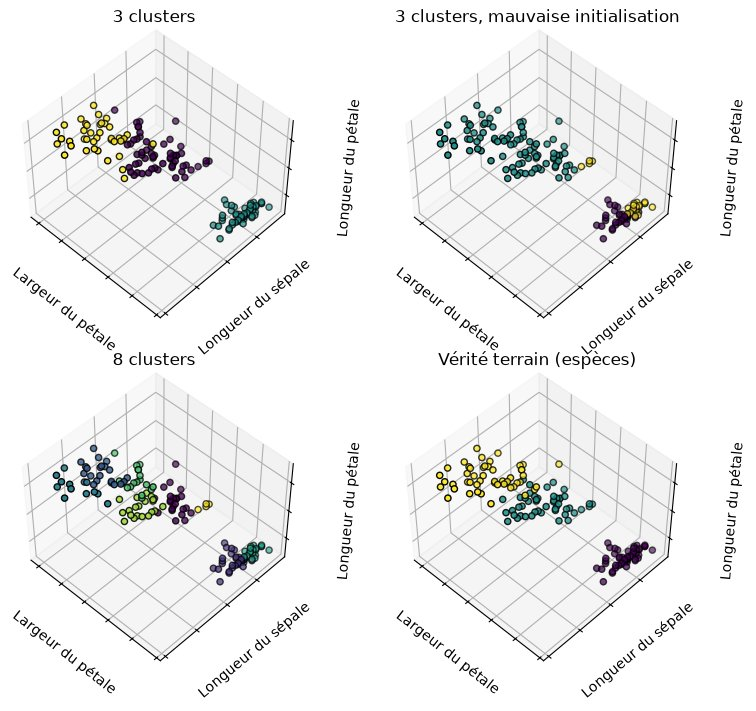

In [4]:
panneaux = [(titre, modele.labels_) for titre, modele in modeles.items()]
panneaux.append(("Vérité terrain (espèces)", y))

fig = plt.figure(figsize=(8, 7))
for i, (titre, etiquettes) in enumerate(panneaux, start=1):
  ax = fig.add_subplot(2, 2, i, projection="3d", elev=48, azim=134)
  ax.scatter(X[:, 3], X[:, 0], X[:, 2], c=etiquettes, edgecolor="k")
  ax.xaxis.set_ticklabels([])
  ax.yaxis.set_ticklabels([])
  ax.zaxis.set_ticklabels([])
  ax.set_xlabel("Largeur du pétale")
  ax.set_ylabel("Longueur du sépale")
  ax.set_zlabel("Longueur du pétale")
  ax.set_title(titre)
plt.tight_layout()
plt.show()

La mauvaise initialisation s'arrête dans un minimum local : inertie 142,8 contre 78,9, ARI 0,43 contre 0,72. Elle regroupe versicolor et virginica et coupe setosa en deux. Les 8 clusters ont l'inertie la plus basse (30,1), mais découpent les espèces en morceaux (ARI 0,46) : l'inertie décroît toujours quand k augmente, elle ne dit pas à elle seule combien de clusters prendre.

## Choisir k

Comme dans les diapositives : l'inertie et la silhouette moyenne pour k de 2 à 8. La silhouette (de −1 à 1) dit si chaque point est plus proche de son cluster que du cluster voisin ; elle se calcule ici sur les 4 variables.

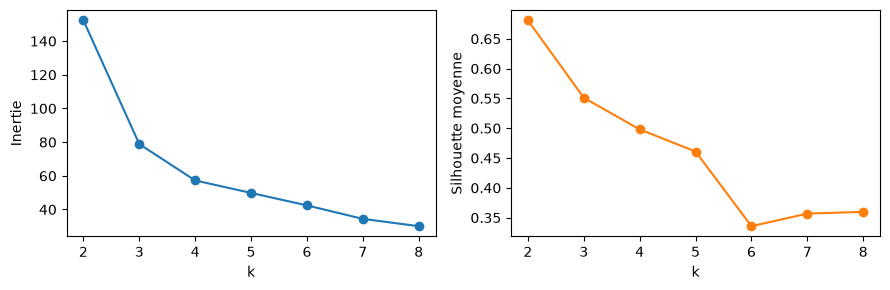

In [5]:
valeurs_k = range(2, 9)
inerties, silhouettes = [], []
for k in valeurs_k:
  modele = KMeans(n_clusters=k, random_state=0).fit(X)
  inerties.append(modele.inertia_)
  silhouettes.append(silhouette_score(X, modele.labels_))

fig, (gauche, droite) = plt.subplots(1, 2, figsize=(9, 3))
gauche.plot(valeurs_k, inerties, "o-")
gauche.set_ylabel("Inertie")
droite.plot(valeurs_k, silhouettes, "o-", color="C1")
droite.set_ylabel("Silhouette moyenne")
for ax in (gauche, droite):
  ax.set_xlabel("k")
plt.tight_layout()
plt.show()

L'inertie décroît toujours : on cherche le coude, pas le minimum. Il est ici à k = 3 (l'inertie perd 73 de 2 à 3 clusters, puis 22 de 3 à 4). La silhouette est la plus haute à k = 2 (0,68) : setosa d'un côté, versicolor et virginica, qui se chevauchent, de l'autre. C'est un indice parmi d'autres : les deux mesures ne s'accordent pas, et c'est la connaissance du domaine (trois espèces) qui tranche.